<a href="https://colab.research.google.com/github/FabioFavre/Simulacoes_Otimizacao/blob/main/Simulacao_2_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simulação 2 — Optimization PNL
**CEFET/RJ — Engenharia de Controle e Automação**

Resolução em Python para Google Colab, com enunciados, métodos, tabelas e gráficos.

**Nota:** o segundo enunciado fala em máximo, mas a função dada é convexa e não possui máximo irrestrito; o gradiente descrito no PDF calcula seu mínimo.

In [ ]:
# ============================================================
# SIMULAÇÃO 2 — OPTIMIZATION PNL | CEFET/RJ
# Métodos de Newton e do Gradiente — Python / Google Colab
# ============================================================
# EXERCÍCIO 1 — ENUNCIADO (páginas 1 e 2):
# "Apresente um programa para encontrar o máximo da função segundo a tabela."
# Método: Newton (aproximação quadrática por Taylor)
# Função: f(x) = 8 + 5x - 3x^4 - 2x^6
# Tabela solicitada: iteração, x_i, f(x_i), f'(x_i), f''(x_i), x_(i+1).
# Como o enunciado não informa x_0, adotamos x_0 = 1.
#
# EXERCÍCIO 2 — ENUNCIADO (páginas 2 e 3):
# "Gradiente, encontrar o max f(x,y) segundo o seguinte procedimento."
# Função do exemplo: f(x,y) = 5x² + 5y² - xy - 2y
# Ponto inicial informado: (0, 0).
# ATENÇÃO: a função é convexa, NÃO tem máximo sem restrições.
# O procedimento da apostila segue passos de DESCIDA e encontra o MÍNIMO.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=8, suppress=True)



## Exercício 1 — Newton (maximização)
**Enunciado:** “Apresente um programa para encontrar o máximo da função segundo a tabela.”

Função: $f(x)=8+5x-3x^4-2x^6$.

A tabela solicitada contém iteração, $x_i$, $f(x_i)$, $f'(x_i)$, $f''(x_i)$ e $x_{i+1}$.

Como o PDF não informa a estimativa inicial, foi adotado $x_0=1$.


1. EXERCÍCIO 1 — MÉTODO DE NEWTON (MAXIMIZAÇÃO)
Enunciado: encontrar o máximo de f(x)=8+5x-3x^4-2x^6
Tabela: iteração | x_i | f(x_i) | f'(x_i) | f''(x_i) | x_(i+1)
Iter.          x_i        f(x_i)       f′(x_i)       f″(x_i)      x_(i+1)
    1    1.0000000     8.0000000   -19.0000000   -96.0000000    0.8020833
    2    0.8020833    10.2362331    -5.1757525   -47.9931580    0.6942398
    3    0.6942398    10.5504000    -0.9504365   -31.2885196    0.6638633
    4    0.6638633    10.5654295    -0.0581890   -27.5194718    0.6617488
    5    0.6617488    10.5654912    -0.0002632   -27.2707998    0.6617391
    6    0.6617391    10.5654912    -0.0000000   -27.2696687    0.6617391
    7    0.6617391    10.5654912    -0.0000000   -27.2696687    0.6617391

Ponto estacionário: x* = 0.6617391410
Valor máximo global: f(x*) = 10.5654911574
Derivada primeira no ponto: f'(x*) = -1.332e-15
Derivada segunda no ponto: f''(x*) = -27.2696687
Verificação: f' é estritamente decrescente e cruza zero uma únic

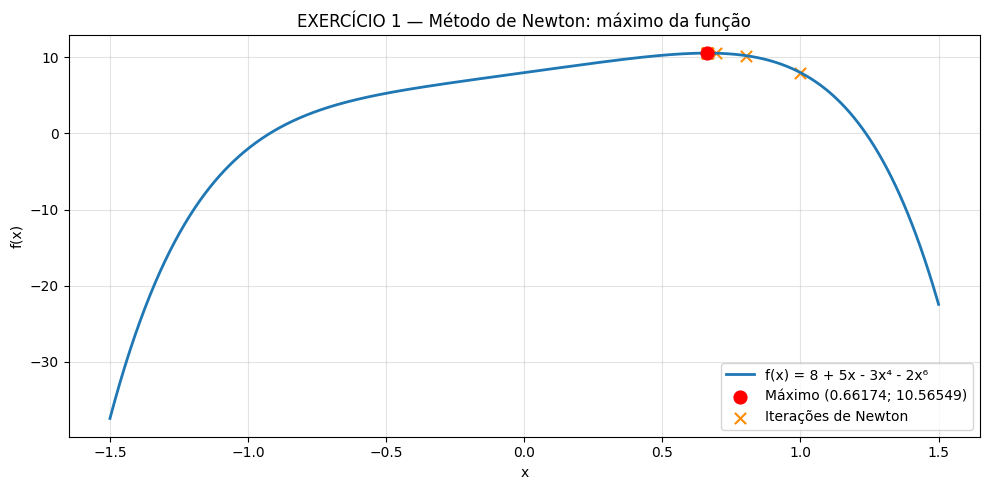

In [ ]:
# ============================================================
# 1. EXERCÍCIO 1 — MÉTODO DE NEWTON PARA MAXIMIZAÇÃO
# ============================================================
print('\n' + '='*79)
print('1. EXERCÍCIO 1 — MÉTODO DE NEWTON (MAXIMIZAÇÃO)')
print('Enunciado: encontrar o máximo de f(x)=8+5x-3x^4-2x^6')
print('Tabela: iteração | x_i | f(x_i) | f\'(x_i) | f\'\'(x_i) | x_(i+1)')
print('='*79)

def f1(x):
    return 8 + 5*x - 3*x**4 - 2*x**6

def df1(x):
    return 5 - 12*x**3 - 12*x**5

def d2f1(x):
    return -36*x**2 - 60*x**4

# Fórmula de Newton: x_(i+1) = x_i - f'(x_i)/f''(x_i).
# x_0 = 1 é uma escolha explícita, porque o PDF não informa x_0.
x = 1.0
tolerancia = 1e-12
max_iter = 30
historico_newton = [x]
linhas_newton = []
for i in range(1, max_iter + 1):
    fx, dfx, d2fx = f1(x), df1(x), d2f1(x)
    if abs(d2fx) < 1e-14:
        raise ArithmeticError('Derivada segunda nula ou muito pequena: altere x_0.')
    proximo = x - dfx/d2fx
    linhas_newton.append((i, x, fx, dfx, d2fx, proximo))
    historico_newton.append(proximo)
    if abs(proximo - x) < tolerancia:
        x = proximo
        break
    x = proximo

print(f"{'Iter.':>5} {'x_i':>12} {'f(x_i)':>13} {'f\u2032(x_i)':>13} {'f\u2033(x_i)':>13} {'x_(i+1)':>12}")
for i, xi, fi, di, ddi, xn in linhas_newton:
    print(f'{i:5d} {xi:12.7f} {fi:13.7f} {di:13.7f} {ddi:13.7f} {xn:12.7f}')

print(f'\nPonto estacionário: x* = {x:.10f}')
print(f'Valor máximo global: f(x*) = {f1(x):.10f}')
print(f'Derivada primeira no ponto: f\'(x*) = {df1(x):.3e}')
print(f'Derivada segunda no ponto: f\'\'(x*) = {d2f1(x):.7f}')
print('Verificação: f\' é estritamente decrescente e cruza zero uma única vez;')
print('além disso, f(x) tende a -infinito quando |x| tende a infinito.')

xx = np.linspace(-1.5, 1.5, 1000)
plt.figure(figsize=(10, 5))
plt.plot(xx, f1(xx), linewidth=2, label='f(x) = 8 + 5x - 3x⁴ - 2x⁶')
plt.scatter([x], [f1(x)], color='red', s=85, zorder=5,
            label=f'Máximo ({x:.5f}; {f1(x):.5f})')
plt.scatter(historico_newton, [f1(v) for v in historico_newton],
            marker='x', color='darkorange', s=65, label='Iterações de Newton')
plt.title('EXERCÍCIO 1 — Método de Newton: máximo da função')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid(alpha=0.35)
plt.legend()
plt.tight_layout()
plt.show()



## Exercício 2 — Gradiente (interpretação correta: minimização)
**Enunciado:** “Gradiente, encontrar o max f(x,y) segundo o seguinte procedimento.”

Função: $f(x,y)=5x^2+5y^2-xy-2y$. Ponto inicial $(0,0)$.

A Hessiana tem autovalores positivos, portanto o problema **não tem máximo sem restrições**. O procedimento mostrado nas páginas 2 e 3 minimiza essa função. O código reproduz as duas primeiras iterações do PDF e continua até a convergência.


2. EXERCÍCIO 2 — MÉTODO DO GRADIENTE
Enunciado: encontrar o "máximo" de f(x,y)=5x²+5y²-xy-2y
Ponto inicial dado: (0, 0)
Observação: sem restrições não existe máximo; calculamos o MÍNIMO.
Autovalores da Hessiana: [ 9. 11.]
Ambos positivos: função estritamente convexa e ilimitada superiormente.
Iter.        x_i        y_i          f_i      grad_x      grad_y         t_i     x_(i+1)     y_(i+1)
    1   0.000000   0.000000    0.0000000    0.000000   -2.000000  -0.1000000    0.000000    0.200000
    2   0.000000   0.200000   -0.2000000   -0.200000    0.000000  -0.1000000    0.020000    0.200000
    3   0.020000   0.200000   -0.2020000    0.000000   -0.020000  -0.1000000    0.020000    0.202000
    4   0.020000   0.202000   -0.2020200   -0.002000    0.000000  -0.1000000    0.020200    0.202000
    5   0.020200   0.202000   -0.2020202   -0.000000   -0.000200  -0.1000000    0.020200    0.202020
    6   0.020200   0.202020   -0.2020202   -0.000020    0.000000  -0.1000000    0.020202    0.20202

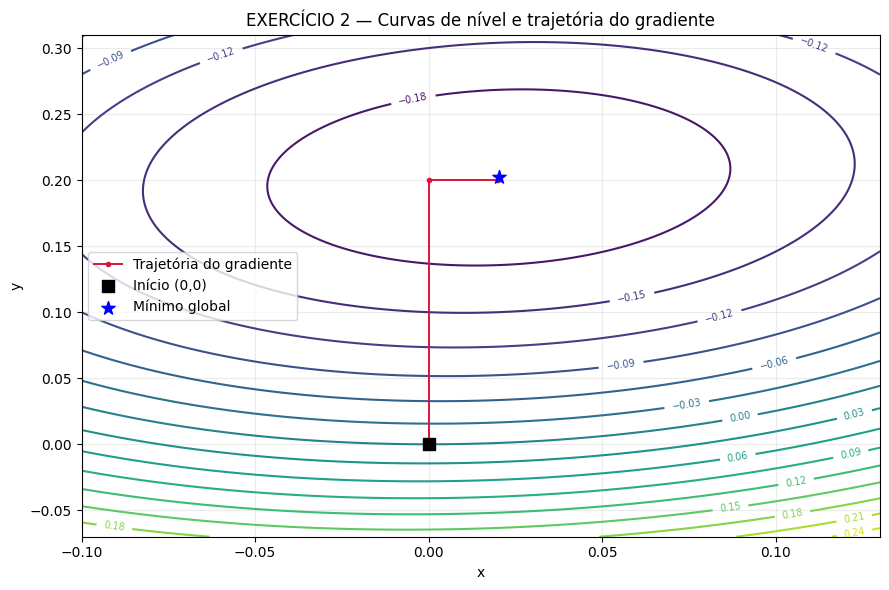

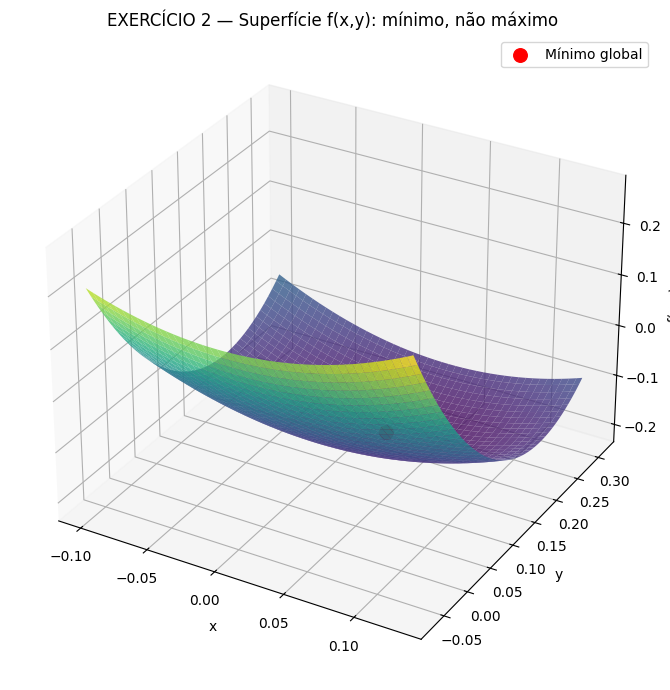

In [ ]:
# ============================================================
# 2. EXERCÍCIO 2 — MÉTODO DO GRADIENTE E BUSCA LINEAR EXATA
# ============================================================
print('\n' + '='*79)
print('2. EXERCÍCIO 2 — MÉTODO DO GRADIENTE')
print('Enunciado: encontrar o "máximo" de f(x,y)=5x²+5y²-xy-2y')
print('Ponto inicial dado: (0, 0)')
print('Observação: sem restrições não existe máximo; calculamos o MÍNIMO.')
print('='*79)

def f2(v):
    x, y = v
    return 5*x*x + 5*y*y - x*y - 2*y

def grad_f2(v):
    x, y = v
    return np.array([10*x-y, 10*y-x-2], dtype=float)

H = np.array([[10., -1.], [-1., 10.]])  # Hessiana
print('Autovalores da Hessiana:', np.linalg.eigvalsh(H))
print('Ambos positivos: função estritamente convexa e ilimitada superiormente.')

# No PDF, x_(i+1) = x_i + t * grad f(x_i), com t negativo.
# Buscando o t que minimiza f(x_i + t grad f(x_i)):
# t = - (g.T @ g) / (g.T @ H @ g).
# Isso equivale à descida do gradiente x_(i+1) = x_i - alpha*g,
# onde alpha = -t é positivo.

v = np.array([0., 0.])
tol_grad = 1e-10
max_iter_grad = 10000
trajetoria = [v.copy()]
linhas_grad = []
for i in range(1, max_iter_grad + 1):
    g = grad_f2(v)
    if np.linalg.norm(g) < tol_grad:
        break
    t = -float(g @ g) / float(g @ H @ g)
    novo = v + t*g
    linhas_grad.append((i, v[0], v[1], f2(v), g[0], g[1], t, novo[0], novo[1]))
    v = novo
    trajetoria.append(v.copy())

print(f"{'Iter.':>5} {'x_i':>10} {'y_i':>10} {'f_i':>12} {'grad_x':>11} {'grad_y':>11} {'t_i':>11} {'x_(i+1)':>11} {'y_(i+1)':>11}")
for i, xi, yi, fi, gx, gy, t, xn, yn in linhas_grad[:12]:
    print(f'{i:5d} {xi:10.6f} {yi:10.6f} {fi:12.7f} {gx:11.6f} {gy:11.6f} {t:11.7f} {xn:11.6f} {yn:11.6f}')
if len(linhas_grad) > 12:
    print(f'... {len(linhas_grad)-12} iterações adicionais omitidas da tabela.')

# Solução analítica independente: H @ v = [0, 2].
v_analitico = np.linalg.solve(H, np.array([0., 2.]))
print('\nConferência com a página 3 do documento:')
print('Após a 1ª iteração, espera-se (0, 1/5) = (0, 0.2).')
print('Após a 2ª iteração, espera-se (1/50, 1/5) = (0.02, 0.2).')
print('Obtido após a 1ª iteração:', trajetoria[1])
print('Obtido após a 2ª iteração:', trajetoria[2])
print(f'\nNúmero de iterações: {len(linhas_grad)}')
print('Ponto encontrado pelo gradiente:', v)
print('Ponto mínimo exato: ', v_analitico)
print(f'Valor mínimo: f(x*,y*) = {f2(v_analitico):.10f}')
print('Máximo global: NÃO EXISTE (função cresce sem limite).')

# Gráfico 2D: curvas de nível e trajetória da descida do gradiente
X, Y = np.meshgrid(np.linspace(-0.10, 0.13, 220),
                   np.linspace(-0.07, 0.31, 220))
Z = 5*X**2 + 5*Y**2 - X*Y - 2*Y
caminho = np.array(trajetoria)
plt.figure(figsize=(9, 6))
cont = plt.contour(X, Y, Z, levels=17, cmap='viridis')
plt.clabel(cont, inline=True, fontsize=7)
plt.plot(caminho[:, 0], caminho[:, 1], 'o-', color='crimson',
         linewidth=1.4, markersize=3, label='Trajetória do gradiente')
plt.scatter([0], [0], color='black', s=75, marker='s', label='Início (0,0)', zorder=5)
plt.scatter([v_analitico[0]], [v_analitico[1]], color='blue',
            s=100, marker='*', label='Mínimo global', zorder=6)
plt.title('EXERCÍCIO 2 — Curvas de nível e trajetória do gradiente')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Gráfico 3D: superfície convexa (recorte visual próximo ao mínimo)
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='viridis', alpha=0.8, edgecolor='none')
ax.scatter([v_analitico[0]], [v_analitico[1]], [f2(v_analitico)],
           color='red', s=95, label='Mínimo global', depthshade=False)
ax.set_title('EXERCÍCIO 2 — Superfície f(x,y): mínimo, não máximo')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('f(x,y)')
ax.legend()
plt.tight_layout()
plt.show()



## Resumo dos resultados

In [ ]:
# ============================================================
# 3. RESUMO FINAL
# ============================================================
print('\n' + '='*79)
print('3. RESUMO FINAL — SIMULAÇÃO 2')
print('='*79)
print(f'Exercício 1: máximo global em x = {x:.8f}; f(x) = {f1(x):.8f}')
print('Exercício 2: não há máximo sem restrições.')
print(f'             mínimo global em (x,y) = ({v_analitico[0]:.8f}, {v_analitico[1]:.8f})')
print(f'             f(x,y) = {f2(v_analitico):.8f}')
print('Fim da Simulação 2.')



3. RESUMO FINAL — SIMULAÇÃO 2
Exercício 1: máximo global em x = 0.66173914; f(x) = 10.56549116
Exercício 2: não há máximo sem restrições.
             mínimo global em (x,y) = (0.02020202, 0.20202020)
             f(x,y) = -0.20202020
Fim da Simulação 2.
